# ResNet18 3D · เพิ่ม seed ให้ `lr0.001_adamw0.001_do0.0_ls0.0` เทียบ `stem_5` (รวม 10 seed)

In [1]:
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)


In [2]:
with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

Train      : 163
Validation : 35
Test       : 36 (ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)


## ตั้งค่า (ปรับตรงนี้)

In [3]:
MODE = "3D"            # ไฟล์นี้ใช้ 3D เท่านั้น
PRETRAINED = False       # 3D สร้างจากศูนย์ ไม่มี pretrained

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
#
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล)
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"

import itertools

BASE = {"STEM_KERNEL": 5, "OPT": "adam", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adam", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adam", 0.0, 0.0, 0.0):
        return "stem_5"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + stem_5 ----------
TOP5 = ["lr0.001_adamw0.001_do0.0_ls0.0"]
LR_ONLY_REF = None
RUN_LIST = ["stem_5"] + TOP5
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_resnet18_3D"                 # โฟลเดอร์เดียวกับไฟล์ ResNet18 3D เดิม (ใช้ผล stem_5 ซ้ำ)
REUSE_FROM = {}                             # ไม่คัดลอกผลจากไฟล์อื่น
os.makedirs(EXP_DIR, exist_ok=True)
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 11 / 60:.1f} ชั่วโมง (ถ้ารันละ ~11 นาที)")


จำนวนชุดทั้ง grid: 420
RUN_LIST 2 ชุด | ยังไม่มีผล 0 รัน | ประมาณ 0.0 ชั่วโมง (ถ้ารันละ ~11 นาที)


## ฟังก์ชันพื้นฐาน และดูความคืบหน้า

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

show_progress()

cuda
เสร็จแล้ว 10 / 10 รัน
สถานะ
เสร็จแล้ว    10


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด
5,lr0.001_adamw0.001_do0.0_ls0.0,1334,เสร็จแล้ว,200/200,36,0.8500,0.7867,11.5,2026-11-03 17:44:10
6,lr0.001_adamw0.001_do0.0_ls0.0,42,เสร็จแล้ว,200/200,16,0.8518,0.7250,11.2,2026-11-07 01:18:29
7,lr0.001_adamw0.001_do0.0_ls0.0,2026,เสร็จแล้ว,200/200,26,0.8006,0.7733,11.1,2026-11-07 01:29:38
8,lr0.001_adamw0.001_do0.0_ls0.0,7,เสร็จแล้ว,200/200,25,0.7555,0.7100,11.2,2026-11-07 04:52:31
9,lr0.001_adamw0.001_do0.0_ls0.0,2002,เสร็จแล้ว,200/200,24,0.7664,0.7233,11.1,2026-11-07 05:03:38


## ข้อมูล และ augmentation

In [5]:
try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


train_data = MRIDataset(train_ids, train=True)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

อินพุตต่อคน: (1, 128, 128, 96)


## ดูตัวอย่างภาพของแต่ละระดับ

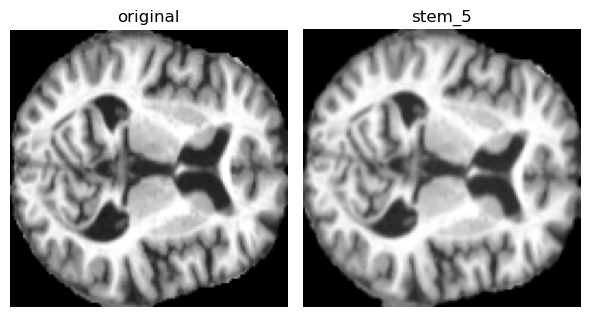

In [6]:
# ดูตัวอย่างภาพของคนแรกใน train ที่แต่ละระดับ (epoch 1, seed แรก) เพื่อเช็กว่า augmentation ทำงานตามที่คิด
prev = MRIDataset(train_ids[:1], train=True)
prev.seed = SEEDS[0]

def axial_slice(x):
    if MODE == "3D":
        return x[0, :, :, x.shape[3] // 2]       # ตัดกลางแกนสุดท้าย (axial)
    return x[-1]                                  # 2D มี 1 ช่อง / 2.5D ช่องสุดท้ายคือ axial

fig, axes = plt.subplots(1, 2, figsize=(3 * (2), 3.4))

prev.rotate_deg, prev.gamma_d, prev.noise_std = 0, 0.0, 0.0
prev.p_rotate, prev.p_gamma = 1.0, 1.0
axes[0].imshow(axial_slice(prev[0][0].numpy()), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("original")
axes[0].axis("off")

for k, name in enumerate(RUN_LIST[:1]):
    p = EXPERIMENTS[name]
    prev.rotate_deg, prev.gamma_d, prev.noise_std = p["ROTATE_DEG"], p["GAMMA_D"], p["NOISE_STD"]
    prev.noise_type = NOISE_TYPE
    prev.p_rotate, prev.p_gamma = p.get("P_ROTATE", 1.0), p.get("P_GAMMA", 1.0)
    axes[k + 1].imshow(axial_slice(prev[0][0].numpy()), cmap="gray", vmin=0, vmax=1)
    axes[k + 1].set_title(name)
    axes[k + 1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "augmentation_preview.png"), dpi=150)
plt.show()

## โมเดล: ResNet18 (3D)

In [7]:
class BasicBlock3D(nn.Module):
    # บล็อกพื้นฐานของ ResNet18: Conv-BN-ReLU-Conv-BN แล้วบวกค่าเดิมกลับเข้าไป (residual) ก่อน ReLU
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_ch)

        # ถ้าขนาด/จำนวนช่องเปลี่ยน ต้องปรับทางลัด (shortcut) ให้ตรงกันก่อนบวก
        if stride == 1 and in_ch == out_ch:
            self.shortcut = nn.Sequential()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm3d(out_ch))

    def forward(self, x):
        y = torch.relu(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        return torch.relu(y + self.shortcut(x))


class ResNet18_3D(nn.Module):
    # ResNet18 แบบ 3 มิติ สร้างจากศูนย์ (ไม่มี pretrained)
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=3):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=3, stride=2, padding=1))

        self.layer1 = nn.Sequential(BasicBlock3D(64, 64), BasicBlock3D(64, 64))
        self.layer2 = nn.Sequential(BasicBlock3D(64, 128, stride=2), BasicBlock3D(128, 128))
        self.layer3 = nn.Sequential(BasicBlock3D(128, 256, stride=2), BasicBlock3D(256, 256))
        self.layer4 = nn.Sequential(BasicBlock3D(256, 512, stride=2), BasicBlock3D(512, 512))

        self.avgpool = nn.AdaptiveAvgPool3d(1)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(512, n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def make_model(stem_kernel, dropout=0.0):
    return ResNet18_3D(in_ch=1, n_classes=2, dropout=dropout, kernel=stem_kernel)

In [12]:
import time, math, torch, torch.nn as nn

def profile(model, x_shape, batch=8, n_train=163, lr=1e-3, steps=20, epochs=200, device="cuda"):
    x = torch.randn(batch, *x_shape, device=device)
    y = torch.randint(0, 2, (batch,), device=device)
    model = model.to(device).train()

    n_all = sum(p.numel() for p in model.parameters())
    n_train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    crit = nn.CrossEntropyLoss()
    def step():
        opt.zero_grad(); crit(model(x), y).backward(); opt.step()

    for _ in range(3): step()
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(steps): step()
    torch.cuda.synchronize()
    sec_per_step = (time.time() - t0) / steps

    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    est_min = sec_per_step * math.ceil(n_train / batch) * epochs / 60
    print(f"พารามิเตอร์ทั้งหมด {n_all:,} | ที่ฝึกได้ {n_train_p:,} | "
          f"หน่วยความจำสูงสุด {peak_gb:.2f} GB | เวลาฝึกโดยประมาณ {est_min:.1f} นาที")

profile(make_model(5), IN_SHAPE)

พารามิเตอร์ทั้งหมด 33,147,074 | ที่ฝึกได้ 33,147,074 | หน่วยความจำสูงสุด 2.22 GB | เวลาฝึกโดยประมาณ 7.0 นาที


## เทรน (ทีละการทดลอง ทีละ seed)

In [8]:
def evaluate(model, loader, criterion):
    # วัดผลบน loader (val) ไม่แตะน้ำหนัก
    model.eval()
    running_loss = 0
    probs, preds, trues = [], [], []

    with torch.no_grad():
        for images, y in loader:
            images = images.to(device)
            y = y.to(device)

            outputs = model(images)
            running_loss += criterion(outputs, y).item()

            probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
            preds.extend(outputs.argmax(1).cpu().numpy())
            trues.extend(y.cpu().numpy())

    tn, fp, fn, tp = confusion_matrix(trues, preds, labels=[0, 1]).ravel()
    return {
        "loss": running_loss / len(loader),
        "AUC": float(roc_auc_score(trues, probs)),
        "Accuracy": float(accuracy_score(trues, preds)),
        "F1": float(f1_score(trues, preds, zero_division=0)),
        "Sensitivity": float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,   # AD ที่ทายถูก / AD ทั้งหมด
        "Specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,   # Normal ที่ทายถูก / Normal ทั้งหมด
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


def write_progress(path, name, seed, status, epoch, best_epoch, best_combo, last_val_auc, minutes):
    d = {"name": name, "seed": seed, "status": status, "epoch": epoch, "epochs": EPOCHS,
         "best_epoch": best_epoch, "best_combo": float(best_combo), "last_val_auc": float(last_val_auc),
         "minutes": round(minutes, 1), "updated": time.strftime("%Y-%m-%d %H:%M:%S")}
    json.dump(d, open(path, "w"), indent=1)


def make_config(p):
    # ค่าตั้งของการทดลอง (ใช้ตัดสินว่าผลที่มีอยู่ตรงกันไหม) key optimizer ใส่เฉพาะ AdamW เพื่อให้ผลของ Adam ที่รันไว้ก่อนหน้ายังใช้ต่อได้
    cfg = {"mode": MODE, "pretrained": PRETRAINED, "stem_kernel": p["STEM_KERNEL"], "lr": p["LR"], "dropout": p["DROPOUT"],
           "weight_decay": p["WD"], "label_smoothing": p["LS"],
           "rotate_deg": p["ROTATE_DEG"], "gamma_d": p["GAMMA_D"], "noise_std": p["NOISE_STD"],
           "noise_type": (NOISE_TYPE if p["NOISE_STD"] > 0 else "gaussian"), "batch_size": BATCH_SIZE, "epochs": EPOCHS}
    if p["OPT"] == "adamw":
        cfg["optimizer"] = "adamw"
    if p.get("P_ROTATE", 1.0) < 1 or p.get("P_GAMMA", 1.0) < 1:
        cfg["p_rotate"], cfg["p_gamma"] = p.get("P_ROTATE", 1.0), p.get("P_GAMMA", 1.0)
    return cfg


def train_one_run(NAME, SEED):
    p = EXPERIMENTS[NAME]
    CONFIG = make_config(p)

    # โฟลเดอร์ของการทดลองนี้: results = ผล (.json) / models = น้ำหนัก (.pt) / progress = ความคืบหน้า / figures = กราฟ
    base = os.path.join(EXP_DIR, NAME)
    for sub in ("results", "models", "progress", "figures"):
        os.makedirs(os.path.join(base, sub), exist_ok=True)
    json_path = os.path.join(base, "results", f"seed{SEED}.json")
    best_pt = os.path.join(base, "models", f"seed{SEED}_best.pt")
    last_pt = os.path.join(base, "models", f"seed{SEED}_last.pt")       # จุดเซฟระหว่างเทรน (ลบเมื่อจบ)
    prog_path = os.path.join(base, "progress", f"seed{SEED}.json")

    # ถ้าเคยรันการตั้งค่านี้แล้วในไฟล์อื่น (REUSE_FROM) และตั้งค่าเหมือนกันทุกอย่าง ให้คัดลอกผลมาใช้ ไม่ต้องเทรนซ้ำ
    if not os.path.exists(json_path) and NAME in REUSE_FROM:
        old_json = os.path.join(REUSE_FROM[NAME], "results", f"seed{SEED}.json")
        old_pt = os.path.join(REUSE_FROM[NAME], "models", f"seed{SEED}_best.pt")
        if os.path.exists(old_json) and os.path.exists(old_pt):
            old = json.load(open(old_json))
            if old["config"] == CONFIG:
                shutil.copy(old_pt, best_pt)
                old["name"] = NAME
                json.dump(old, open(json_path, "w"), indent=1)
                write_progress(prog_path, NAME, SEED, "เสร็จแล้ว", EPOCHS, old["best_epoch"], old["best_combo"],
                               old["history"]["val_auc"][-1], old["minutes"])
                print(f"[{NAME}] seed {SEED}: ใช้ผลที่รันไว้แล้วจาก {REUSE_FROM[NAME]}")

    # ถ้ารันเสร็จแล้ว (และตั้งค่าเหมือนเดิม) ให้ข้าม
    if os.path.exists(json_path) and os.path.exists(best_pt):
        if json.load(open(json_path))["config"] == CONFIG:
            print(f"[{NAME}] seed {SEED}: มีผลแล้ว ข้ามไป")
            return

    print("=" * 60)
    print(f"การทดลอง {NAME} | stem kernel {p['STEM_KERNEL']} | {p['OPT']} lr={p['LR']} wd={p['WD']} dropout={p['DROPOUT']} ls={p['LS']} | SEED = {SEED}")
    print("=" * 60)

    set_seed(SEED)
    model = make_model(p["STEM_KERNEL"], p["DROPOUT"]).to(device)
    print("จำนวน parameter:", f"{sum(q.numel() for q in model.parameters()):,}")

    criterion = nn.CrossEntropyLoss(label_smoothing=p["LS"])
    opt_cls = optim.AdamW if p["OPT"] == "adamw" else optim.Adam
    optimizer = opt_cls(model.parameters(), lr=p["LR"], weight_decay=p["WD"])

    # ตั้งค่า augmentation ของ train ตามระดับของการทดลองนี้
    train_data.seed = SEED
    train_data.rotate_deg = p["ROTATE_DEG"]
    train_data.gamma_d = p["GAMMA_D"]
    train_data.noise_std = p["NOISE_STD"]
    train_data.noise_type = NOISE_TYPE
    train_data.p_rotate = p.get("P_ROTATE", 1.0)
    train_data.p_gamma = p.get("P_GAMMA", 1.0)

    names = ["train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1", "val_auc", "val_sens", "val_spec"]
    hist = {k: [] for k in names}
    best_combo, best_epoch, best_val, best_state = -1, -1, None, None
    start_epoch = 0
    minutes_before = 0.0

    # ถ้ามีจุดเซฟค้างอยู่ (เคยรันแล้วหลุดกลางทาง และตั้งค่าเหมือนเดิม) ให้เริ่มต่อจากจุดนั้น
    ck = None
    if os.path.exists(last_pt):
        try:
            ck = torch.load(last_pt, map_location=device, weights_only=False)
        except Exception as e:                  # ไฟล์เซฟเสีย (เช่นหลุดตอนเซฟ) -> ทิ้งแล้วเริ่มรันนี้ใหม่จาก epoch 1
            print(f"จุดเซฟเสีย ({type(e).__name__}) ลบทิ้งแล้วเริ่มใหม่")
            os.remove(last_pt)
            ck = None
    if ck is not None:
        if ck["config"] == CONFIG:
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])
            hist, best_combo, best_epoch = ck["hist"], ck["best_combo"], ck["best_epoch"]
            best_val, best_state = ck["best_val"], ck["best_state"]
            start_epoch, minutes_before = ck["epoch"], ck["minutes"]
            print(f"เริ่มต่อจาก epoch {start_epoch + 1} (มีจุดเซฟอยู่)")

    t_start = time.time()
    g = torch.Generator()

    for epoch in range(start_epoch, EPOCHS):

        # ---------- train ----------
        train_data.epoch = epoch + 1
        g.manual_seed(SEED * 1000 + epoch)          # ลำดับสลับภาพของแต่ละ epoch ผูกกับ (seed, epoch)
        train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=NUM_WORKERS)

        model.train()
        running_loss = 0
        train_preds, train_trues = [], []

        pbar = tqdm(train_loader, desc=f"{NAME} seed {SEED} epoch {epoch+1}/{EPOCHS}", leave=False)
        for images, y in pbar:
            images = images.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            train_preds.extend(outputs.argmax(1).cpu().numpy())
            train_trues.extend(y.cpu().numpy())
            pbar.set_postfix(loss=loss.item())

        train_loss = running_loss / len(train_loader)
        train_acc = accuracy_score(train_trues, train_preds)
        train_f1 = f1_score(train_trues, train_preds, zero_division=0)

        # ---------- validation (ไม่ทำ augmentation) ----------
        v = evaluate(model, val_loader, criterion)

        hist["train_loss"].append(float(train_loss))
        hist["train_acc"].append(float(train_acc))
        hist["train_f1"].append(float(train_f1))
        hist["val_loss"].append(v["loss"])
        hist["val_acc"].append(v["Accuracy"])
        hist["val_f1"].append(v["F1"])
        hist["val_auc"].append(v["AUC"])
        hist["val_sens"].append(v["Sensitivity"])
        hist["val_spec"].append(v["Specificity"])

        # ---------- เลือก epoch ที่ดีที่สุดจาก val: (AUC + F1) / 2 สูงสุด ----------
        combo_score = (v["AUC"] + v["F1"]) / 2
        if combo_score > best_combo:
            best_combo = combo_score
            best_epoch = epoch + 1
            best_val = {k: v[k] for k in ("AUC", "Accuracy", "F1", "Sensitivity", "Specificity", "TN", "FP", "FN", "TP")}
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

        minutes = minutes_before + (time.time() - t_start) / 60
        write_progress(prog_path, NAME, SEED, "กำลังรัน", epoch + 1, best_epoch, best_combo, v["AUC"], minutes)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss {train_loss:.4f} | Val Loss {v['loss']:.4f} | "
                  f"AUC {v['AUC']:.4f} | F1 {v['F1']:.4f} | Sens {v['Sensitivity']:.3f} | Spec {v['Specificity']:.3f}")

        # ---------- เซฟจุดต่อ (ถ้าหลุดกลางทาง รันซ้ำจะเริ่มต่อจากตรงนี้) ----------
        if (epoch + 1) % CHECKPOINT_EVERY == 0 and (epoch + 1) < EPOCHS:
            tmp_pt = last_pt + ".tmp"           # เซฟลงไฟล์ชั่วคราวก่อน แล้วค่อยสลับชื่อ (กันไฟล์เสียถ้าหลุดตอนเซฟ)
            torch.save({"config": CONFIG, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "hist": hist, "best_combo": best_combo, "best_epoch": best_epoch,
                        "best_val": best_val, "best_state": best_state,
                        "epoch": epoch + 1, "minutes": minutes}, tmp_pt)
            os.replace(tmp_pt, last_pt)

    # ---------- จบ: เก็บน้ำหนัก (.pt) และผล (.json) ----------
    minutes = minutes_before + (time.time() - t_start) / 60
    torch.save(best_state, best_pt)

    result = {
        "name": NAME,
        "seed": SEED,
        "config": CONFIG,
        "best_epoch": best_epoch,
        "best_combo": float(best_combo),
        "val_best": best_val,
        "val_last": {"AUC": hist["val_auc"][-1], "Accuracy": hist["val_acc"][-1], "F1": hist["val_f1"][-1],
                     "Sensitivity": hist["val_sens"][-1], "Specificity": hist["val_spec"][-1]},
        "minutes": round(minutes, 1),
        "history": hist,
    }
    json.dump(result, open(json_path, "w"), indent=1)
    write_progress(prog_path, NAME, SEED, "เสร็จแล้ว", EPOCHS, best_epoch, best_combo, hist["val_auc"][-1], minutes)
    if os.path.exists(last_pt):
        os.remove(last_pt)

    print()
    print(f"[{NAME}] seed {SEED} เสร็จแล้ว best_epoch: {best_epoch} | combo: {best_combo:.4f} | ใช้เวลา {result['minutes']} นาที")
    print()


for NAME in RUN_LIST:
    for SEED in SEEDS:
        train_one_run(NAME, SEED)

show_progress()

[stem_5] seed 1334: มีผลแล้ว ข้ามไป
[stem_5] seed 42: มีผลแล้ว ข้ามไป
[stem_5] seed 2026: มีผลแล้ว ข้ามไป
[stem_5] seed 7: มีผลแล้ว ข้ามไป
[stem_5] seed 2002: มีผลแล้ว ข้ามไป
[lr0.001_adamw0.001_do0.0_ls0.0] seed 1334: มีผลแล้ว ข้ามไป
[lr0.001_adamw0.001_do0.0_ls0.0] seed 42: มีผลแล้ว ข้ามไป
[lr0.001_adamw0.001_do0.0_ls0.0] seed 2026: มีผลแล้ว ข้ามไป
[lr0.001_adamw0.001_do0.0_ls0.0] seed 7: มีผลแล้ว ข้ามไป
[lr0.001_adamw0.001_do0.0_ls0.0] seed 2002: มีผลแล้ว ข้ามไป
เสร็จแล้ว 10 / 10 รัน
สถานะ
เสร็จแล้ว    10


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด
5,lr0.001_adamw0.001_do0.0_ls0.0,1334,เสร็จแล้ว,200/200,36,0.8500,0.7867,11.5,2026-11-03 17:44:10
6,lr0.001_adamw0.001_do0.0_ls0.0,42,เสร็จแล้ว,200/200,16,0.8518,0.7250,11.2,2026-11-07 01:18:29
7,lr0.001_adamw0.001_do0.0_ls0.0,2026,เสร็จแล้ว,200/200,26,0.8006,0.7733,11.1,2026-11-07 01:29:38
8,lr0.001_adamw0.001_do0.0_ls0.0,7,เสร็จแล้ว,200/200,25,0.7555,0.7100,11.2,2026-11-07 04:52:31
9,lr0.001_adamw0.001_do0.0_ls0.0,2002,เสร็จแล้ว,200/200,24,0.7664,0.7233,11.1,2026-11-07 05:03:38


## ผลสุดท้าย (Validation): Accuracy, F1, AUC, Sensitivity, Specificity

In [9]:
# ---------- อ่านผลทุกการทดลองจากไฟล์ .json (ไม่ต้องเทรนซ้ำ) ----------
def load_runs(name):
    runs = []
    for s in SEEDS:
        p = os.path.join(EXP_DIR, name, "results", f"seed{s}.json")
        if os.path.exists(p):
            runs.append(json.load(open(p)))
    return runs

all_runs = {name: load_runs(name) for name in RUN_LIST}
all_runs = {n: r for n, r in all_runs.items() if len(r) > 0}          # เฉพาะชุดที่รันเสร็จแล้ว
METRICS = ["AUC", "F1", "Accuracy", "Sensitivity", "Specificity"]
N_AD, N_NORMAL = 15, 20                                                # val: AD 15 คน, Normal 20 คน (1 คน = 0.067 sens / 0.05 spec)
print(f"มีผลแล้ว {len(all_runs)} ชุด จาก RUN_LIST {len(RUN_LIST)} ชุด | seed ที่ใช้: {SEEDS}")
print(f"จำนวนชุดที่ลองบน val เดียวกันทั้งหมด (ต้องเปิดเผยตอนรายงาน): {len(EXPERIMENTS)} ชุด (คัดกรอง 1 seed) + รันซ้ำหลาย seed ที่นี่ (10 seed ในชุดที่ชี้ขาด)")
for n, r in all_runs.items():
    if len(r) < len(SEEDS):
        print(f"  ! {n}: มีผลแค่ {len(r)}/{len(SEEDS)} seed")

# ตารางต่อ seed (เก็บลง csv)
rows = []
for name, runs in all_runs.items():
    for r in runs:
        h = r["history"]
        row = {"การทดลอง": name, "seed": r["seed"], "best_epoch": r["best_epoch"]}
        for m in METRICS:
            row[f"{m} (best)"] = r["val_best"][m]
        for m in ("AUC", "F1"):
            row[f"{m} (epoch สุดท้าย)"] = r["val_last"][m]
        row["train loss (สุดท้าย)"] = h["train_loss"][-1]
        row["val loss ต่ำสุด"] = min(h["val_loss"])
        row["val loss (สุดท้าย)"] = h["val_loss"][-1]
        rows.append(row)
per_seed = pd.DataFrame(rows)
per_seed.to_csv(os.path.join(EXP_DIR, "summary_top5_per_seed.csv"), index=False)
print("\nผลรายรัน (ทุก seed):")
display(per_seed.sort_values(["การทดลอง", "seed"]).round(3).reset_index(drop=True))

# ---------- สรุปข้าม seed: mean ± SD และเทียบ control ตามเกณฑ์ที่ล็อกไว้ ----------
REF = "stem_5"
FRESH = [s for s in SEEDS if s != 1334]      # seed ที่ไม่ได้ถูกใช้คัดเลือกชุด (ไม่มี selection bias) เพราะ 1334 คือ seed ที่ใช้คัดกรอง 420 ชุด


def settings_of(name):
    p = EXPERIMENTS[name]
    return f"lr={p['LR']}, {p['OPT']} wd={p['WD']}, do={p['DROPOUT']}, ls={p['LS']}"


def build(key):
    out = []
    for name, runs in all_runs.items():
        row = {"การทดลอง": name, "ตั้งค่า": settings_of(name), "n seed": len(runs)}
        for m in METRICS:
            v = [r[key][m] for r in runs]
            row[m] = float(np.mean(v))
            row[m + " SD"] = float(np.std(v, ddof=1)) if len(v) > 1 else float("nan")
        fresh = [r[key]["AUC"] for r in runs if r["seed"] in FRESH]
        row["AUC (เฉพาะ seed ใหม่)"] = float(np.mean(fresh)) if fresh else float("nan")
        row["train loss (สุดท้าย)"] = float(np.mean([r["history"]["train_loss"][-1] for r in runs]))
        row["val loss (สุดท้าย)"] = float(np.mean([r["history"]["val_loss"][-1] for r in runs]))
        out.append(row)
    return pd.DataFrame(out)


def verdict(row, ref):
    # เกณฑ์ล็อกไว้: AUC ต่าง > 0.01 -> F1 ต่าง > 0.02 -> sens/spec (ดูเอง) -> เลือกที่ง่ายกว่า
    dA, dF = row["AUC"] - ref["AUC"], row["F1"] - ref["F1"]
    if dA > 0.01:   return "ดีกว่า (AUC)"
    if dA < -0.01:  return "แย่กว่า (AUC)"
    if dF > 0.02:   return "ดีกว่า (F1)"
    if dF < -0.02:  return "แย่กว่า (F1)"
    return "เสมอ -> ดู sens/spec / เลือกที่ง่ายกว่า"


def compare(tbl, ref_name, extra_ref=None):
    ref = tbl[tbl["การทดลอง"] == ref_name].iloc[0]
    t = tbl.copy()
    t["ΔAUC vs control"] = t["AUC"] - ref["AUC"]
    t["ΔF1 vs control"] = t["F1"] - ref["F1"]
    t["ΔSens (คน AD)"] = (t["Sensitivity"] - ref["Sensitivity"]) * N_AD
    t["ΔSpec (คน Normal)"] = (t["Specificity"] - ref["Specificity"]) * N_NORMAL
    t["ผลเทียบ control"] = [("-" if r["การทดลอง"] == ref_name else verdict(r, ref)) for _, r in t.iterrows()]
    if extra_ref is not None and extra_ref in set(t["การทดลอง"]):
        er = t[t["การทดลอง"] == extra_ref].iloc[0]
        t["ผลเทียบ LR-only"] = [("-" if r["การทดลอง"] in (ref_name, extra_ref) else verdict(r, er)) for _, r in t.iterrows()]
    t["overfit: val loss - train loss"] = t["val loss (สุดท้าย)"] - t["train loss (สุดท้าย)"]
    return t.sort_values(["AUC", "F1"], ascending=False).reset_index(drop=True)


assert REF in all_runs, "ยังไม่มีผลของ control"
tbl_best = build("val_best")
tbl_last = build("val_last")
cmp_best = compare(tbl_best, REF, LR_ONLY_REF)
cmp_last = compare(tbl_last, REF, LR_ONLY_REF)
cmp_best.to_csv(os.path.join(EXP_DIR, "summary_top5_best_epoch.csv"), index=False)
cmp_last.to_csv(os.path.join(EXP_DIR, "summary_top5_last_epoch.csv"), index=False)

SHOW = ["การทดลอง", "n seed", "AUC", "AUC SD", "F1", "F1 SD", "Sensitivity", "Specificity",
        "AUC (เฉพาะ seed ใหม่)", "ΔAUC vs control", "ΔF1 vs control", "ΔSens (คน AD)", "ΔSpec (คน Normal)", "ผลเทียบ control"]
if LR_ONLY_REF in all_runs:
    SHOW.append("ผลเทียบ LR-only")
SHOW.append("overfit: val loss - train loss")
print("\n=== epoch ที่เลือกจาก val ((AUC + F1) / 2 สูงสุด) mean ± SD ข้าม seed ===")
display(cmp_best[SHOW].round(3))
print("\n=== epoch สุดท้าย (ไม่ได้เลือก epoch) mean ± SD ข้าม seed ===")
display(cmp_last[SHOW].round(3))
print("\nหมายเหตุ: seed 1334 คือ seed ที่ใช้คัดชุดเหล่านี้จาก 420 ชุด จึงถูกเลือกเพราะ 'ดวงดี' ใน seed นี้ ค่าเฉลี่ยข้าม seed จึงเอนเอียงขึ้นเล็กน้อย "
      "คอลัมน์ 'AUC (เฉพาะ seed ใหม่)' (ทุก seed ยกเว้น 1334) คือค่าที่ไม่มี selection bias ใช้ดูว่าความดีที่เห็นยังอยู่ไหม")


มีผลแล้ว 2 ชุด จาก RUN_LIST 2 ชุด | seed ที่ใช้: [1334, 42, 2026, 7, 2002]
จำนวนชุดที่ลองบน val เดียวกันทั้งหมด (ต้องเปิดเผยตอนรายงาน): 420 ชุด (คัดกรอง 1 seed) + รันซ้ำหลาย seed ที่นี่ (10 seed ในชุดที่ชี้ขาด)

ผลรายรัน (ทุก seed):


,การทดลอง,seed,best_epoch,AUC (best),F1 (best),Accuracy (best),Sensitivity (best),Specificity (best),AUC (epoch สุดท้าย),F1 (epoch สุดท้าย),train loss (สุดท้าย),val loss ต่ำสุด,val loss (สุดท้าย)
0,lr0.001_adamw0.001_do0.0_ls0.0,7,25,0.813,0.698,0.629,1.000,0.35,0.710,0.667,0.022,0.505,2.406
1,lr0.001_adamw0.001_do0.0_ls0.0,42,16,0.880,0.824,0.829,0.933,0.75,0.725,0.606,0.001,0.442,2.253
2,lr0.001_adamw0.001_do0.0_ls0.0,1334,36,0.900,0.800,0.800,0.933,0.70,0.787,0.667,0.049,0.427,2.010
3,lr0.001_adamw0.001_do0.0_ls0.0,2002,24,0.790,0.743,0.743,0.867,0.65,0.723,0.625,0.003,0.488,1.602
4,lr0.001_adamw0.001_do0.0_ls0.0,2026,26,0.883,0.718,0.686,0.933,0.50,0.773,0.581,0.000,0.458,2.272
5,stem_5,7,15,0.793,0.750,0.771,0.800,0.75,0.660,0.647,0.001,0.548,2.699
6,stem_5,42,32,0.813,0.800,0.800,0.933,0.70,0.745,0.647,0.008,0.482,2.125
7,stem_5,1334,146,0.820,0.800,0.800,0.933,0.70,0.823,0.609,0.042,0.481,1.394
8,stem_5,2002,115,0.800,0.757,0.743,0.933,0.60,0.727,0.647,0.000,0.546,1.960
9,stem_5,2026,43,0.813,0.788,0.800,0.867,0.75,0.762,0.645,0.136,0.528,1.682



=== epoch ที่เลือกจาก val ((AUC + F1) / 2 สูงสุด) mean ± SD ข้าม seed ===


,การทดลอง,n seed,AUC,AUC SD,F1,F1 SD,Sensitivity,Specificity,AUC (เฉพาะ seed ใหม่),ΔAUC vs control,ΔF1 vs control,ΔSens (คน AD),ΔSpec (คน Normal),ผลเทียบ control,overfit: val loss - train loss
0,lr0.001_adamw0.001_do0.0_ls0.0,5,0.853,0.048,0.756,0.054,0.933,0.59,0.842,0.045,-0.023,0.6,-2.2,ดีกว่า (AUC),2.094
1,stem_5,5,0.808,0.011,0.779,0.024,0.893,0.70,0.805,0.000,0.000,0.0,0.0,-,1.934



=== epoch สุดท้าย (ไม่ได้เลือก epoch) mean ± SD ข้าม seed ===


,การทดลอง,n seed,AUC,AUC SD,F1,F1 SD,Sensitivity,Specificity,AUC (เฉพาะ seed ใหม่),ΔAUC vs control,ΔF1 vs control,ΔSens (คน AD),ΔSpec (คน Normal),ผลเทียบ control,overfit: val loss - train loss
0,lr0.001_adamw0.001_do0.0_ls0.0,5,0.744,0.034,0.629,0.038,0.733,0.56,0.733,0.0,-0.01,1.0,-2.6,เสมอ -> ดู sens/spec / เลือกที่ง่ายกว่า,2.094
1,stem_5,5,0.743,0.059,0.639,0.017,0.667,0.69,0.723,0.0,0.00,0.0,0.0,-,1.934



หมายเหตุ: seed 1334 คือ seed ที่ใช้คัดชุดเหล่านี้จาก 420 ชุด จึงถูกเลือกเพราะ 'ดวงดี' ใน seed นี้ ค่าเฉลี่ยข้าม seed จึงเอนเอียงขึ้นเล็กน้อย คอลัมน์ 'AUC (เฉพาะ seed ใหม่)' (ทุก seed ยกเว้น 1334) คือค่าที่ไม่มี selection bias ใช้ดูว่าความดีที่เห็นยังอยู่ไหม


In [10]:
# ---------- ตัดสินตามเกณฑ์ที่ล็อกไว้ (AUC ก่อน ที่ best epoch) ----------
r = cmp_best[cmp_best["การทดลอง"] == "lr0.001_adamw0.001_do0.0_ls0.0"].iloc[0]
c = cmp_best[cmp_best["การทดลอง"] == REF].iloc[0]
print(f"best epoch (mean {int(r['n seed'])} seed): lr0.001_adamw0.001_do0.0_ls0.0 AUC {r['AUC']:.3f} ± {r['AUC SD']:.3f} | stem_5 AUC {c['AUC']:.3f} ± {c['AUC SD']:.3f} | ต่าง {r['ΔAUC vs control']:+.3f}")
print("F1 :", f"{r['F1']:.3f} vs {c['F1']:.3f} | ΔSens {r['ΔSens (คน AD)']:+.1f} คน | ΔSpec {r['ΔSpec (คน Normal)']:+.1f} คน")
print("ผลตามเกณฑ์:", r["ผลเทียบ control"])
last = cmp_last[cmp_last["การทดลอง"] == "lr0.001_adamw0.001_do0.0_ls0.0"].iloc[0]
print(f"(ประกอบ) epoch สุดท้าย: AUC {last['AUC']:.3f} | ΔAUC {last['ΔAUC vs control']:+.3f} | F1 {last['F1']:.3f} | {last['ผลเทียบ control']}")
print("(ประกอบ) AUC เฉพาะ seed ที่ไม่ใช่ 1334:", round(r["AUC (เฉพาะ seed ใหม่)"], 3), "vs", round(c["AUC (เฉพาะ seed ใหม่)"], 3))
print("\nรายงานคู่กัน: คัดจาก 420 ชุด, เพิ่ม seed หลังเห็นผล, SD ข้าม seed, ผลของ epoch สุดท้าย")


best epoch (mean 5 seed): lr0.001_adamw0.001_do0.0_ls0.0 AUC 0.853 ± 0.048 | stem_5 AUC 0.808 ± 0.011 | ต่าง +0.045
F1 : 0.756 vs 0.779 | ΔSens +0.6 คน | ΔSpec -2.2 คน
ผลตามเกณฑ์: ดีกว่า (AUC)
(ประกอบ) epoch สุดท้าย: AUC 0.744 | ΔAUC +0.000 | F1 0.629 | เสมอ -> ดู sens/spec / เลือกที่ง่ายกว่า
(ประกอบ) AUC เฉพาะ seed ที่ไม่ใช่ 1334: 0.842 vs 0.805

รายงานคู่กัน: คัดจาก 420 ชุด, เพิ่ม seed หลังเห็นผล, SD ข้าม seed, ผลของ epoch สุดท้าย


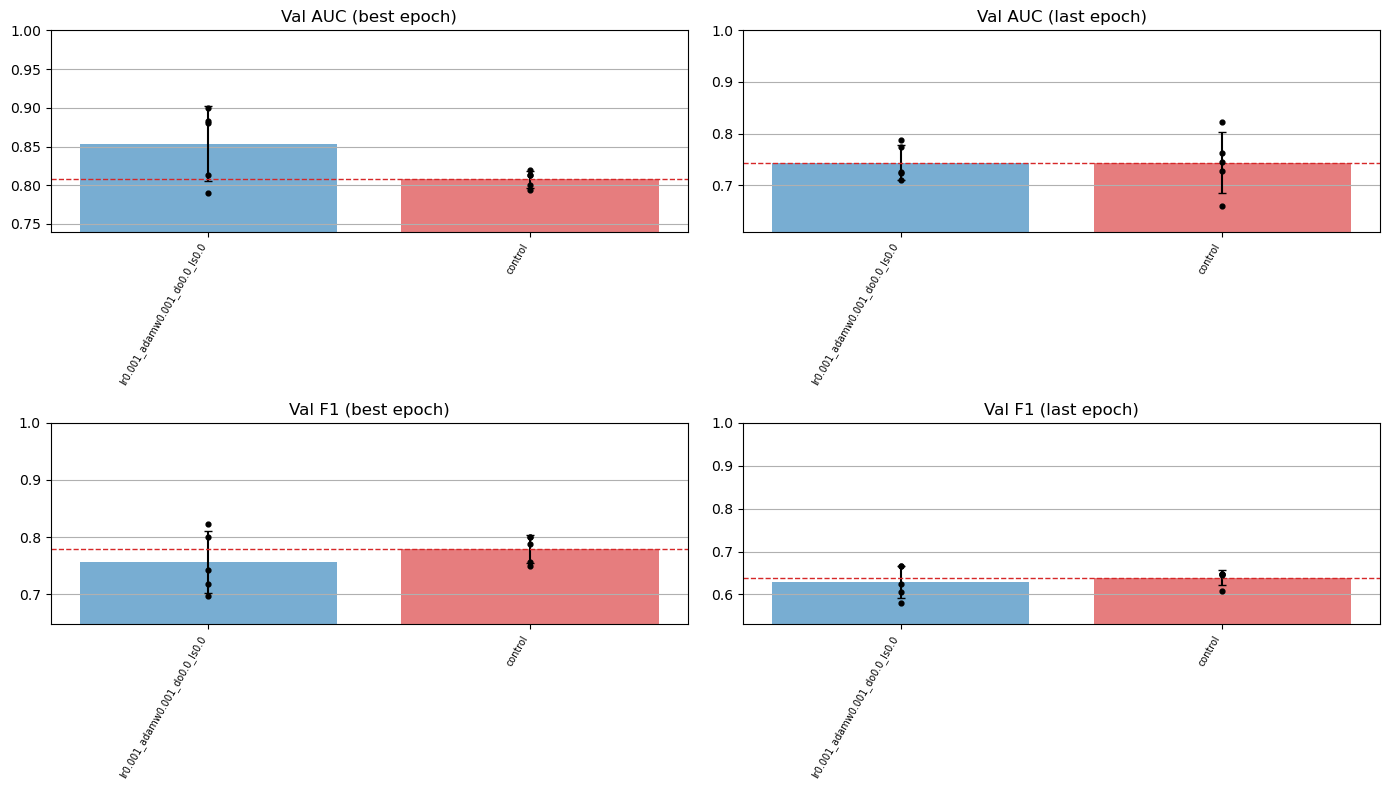

In [11]:
# ---------- กราฟ: AUC / F1 ต่อชุด (จุด = แต่ละ seed, แท่ง = mean ± SD) เทียบ control ----------
order = cmp_best["การทดลอง"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (key, met, title) in zip(axes.ravel(), (("val_best", "AUC", "Val AUC (best epoch)"), ("val_last", "AUC", "Val AUC (last epoch)"),
                                              ("val_best", "F1", "Val F1 (best epoch)"), ("val_last", "F1", "Val F1 (last epoch)"))):
    means, sds, pts = [], [], []
    for n in order:
        v = [r[key][met] for r in all_runs[n]]
        means.append(np.mean(v)); sds.append(np.std(v, ddof=1) if len(v) > 1 else 0); pts.append(v)
    x = np.arange(len(order))
    colors = ["tab:red" if n == REF else ("tab:green" if n == LR_ONLY_REF else "tab:blue") for n in order]
    ax.bar(x, means, yerr=sds, color=colors, alpha=0.6, capsize=3)
    for xi, v in zip(x, pts):
        ax.scatter([xi] * len(v), v, color="black", s=12, zorder=3)
    ref_mean = means[order.index(REF)]
    ax.axhline(ref_mean, color="tab:red", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels([("control" if n == REF else n) for n in order], rotation=60, ha="right", fontsize=7)
    lo = min(min(v) for v in pts)
    ax.set_ylim(max(0, lo - 0.05), 1.0)
    ax.set_title(title)
    ax.grid(True, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "compare_top5.png"), dpi=150)
plt.show()


## กราฟ 2x2 ของแต่ละ seed

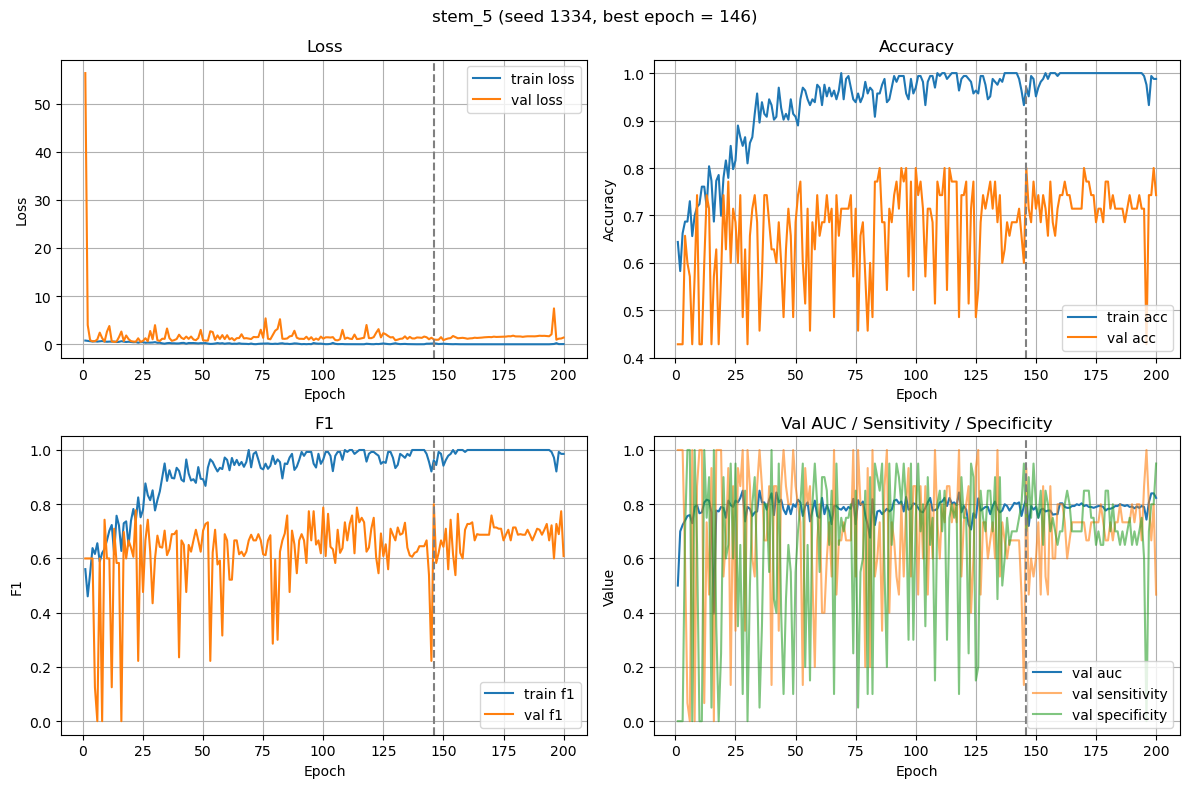

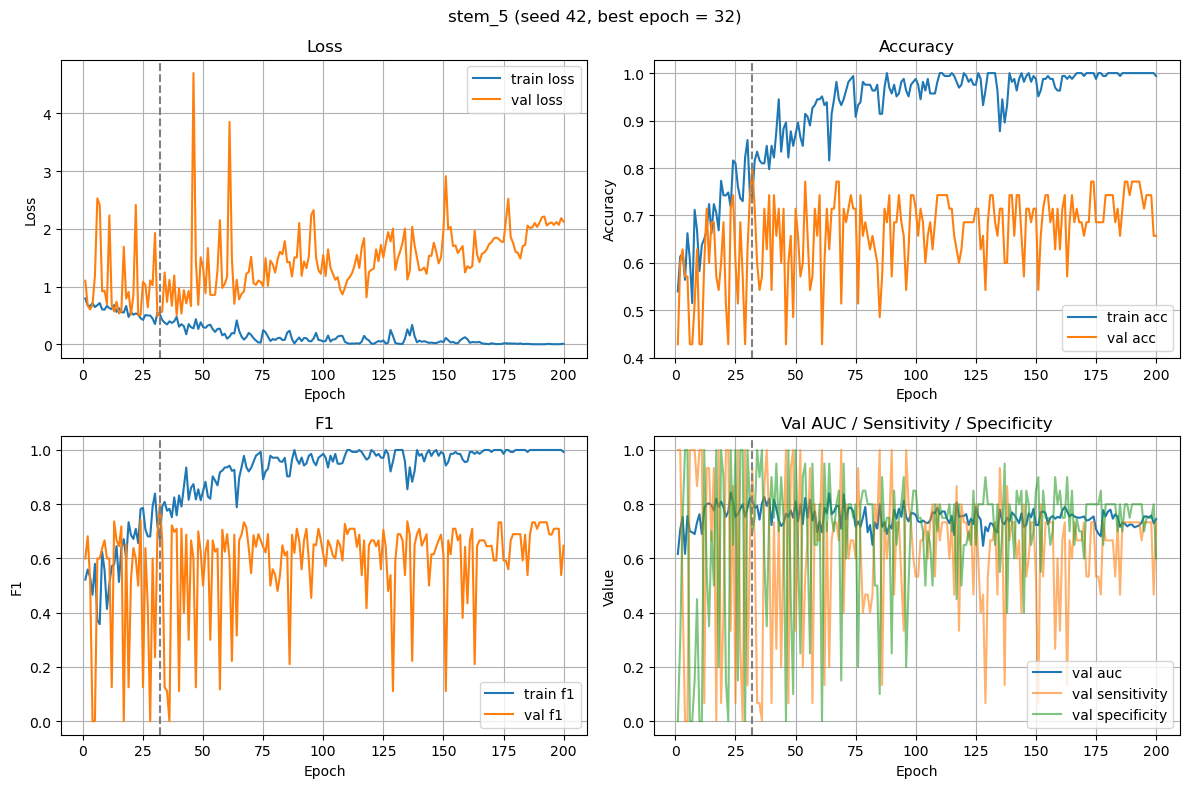

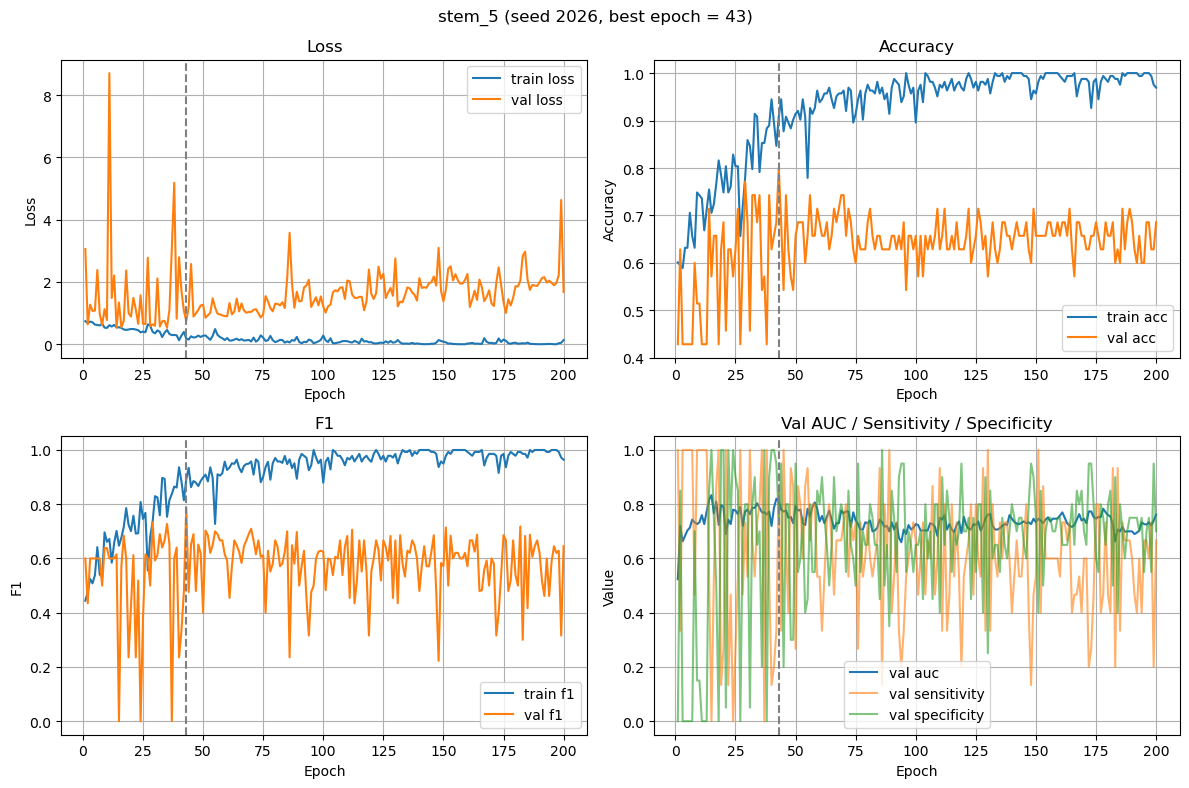

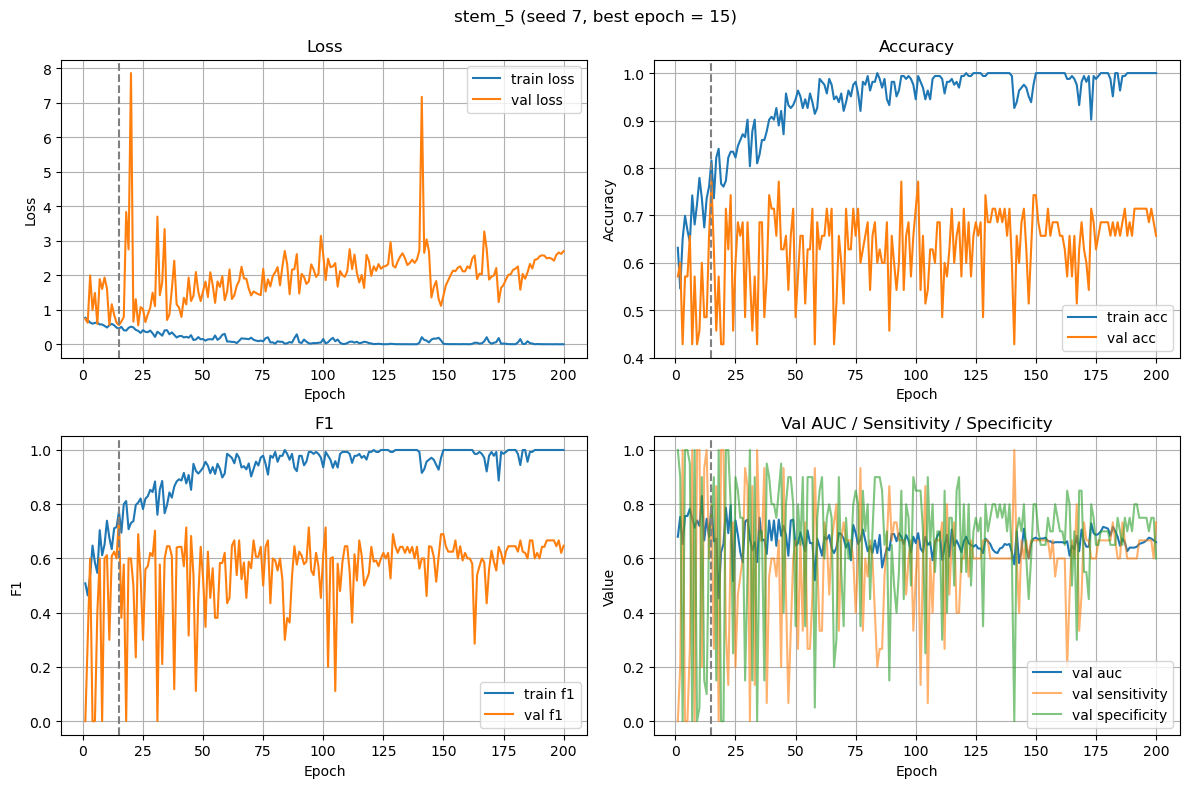

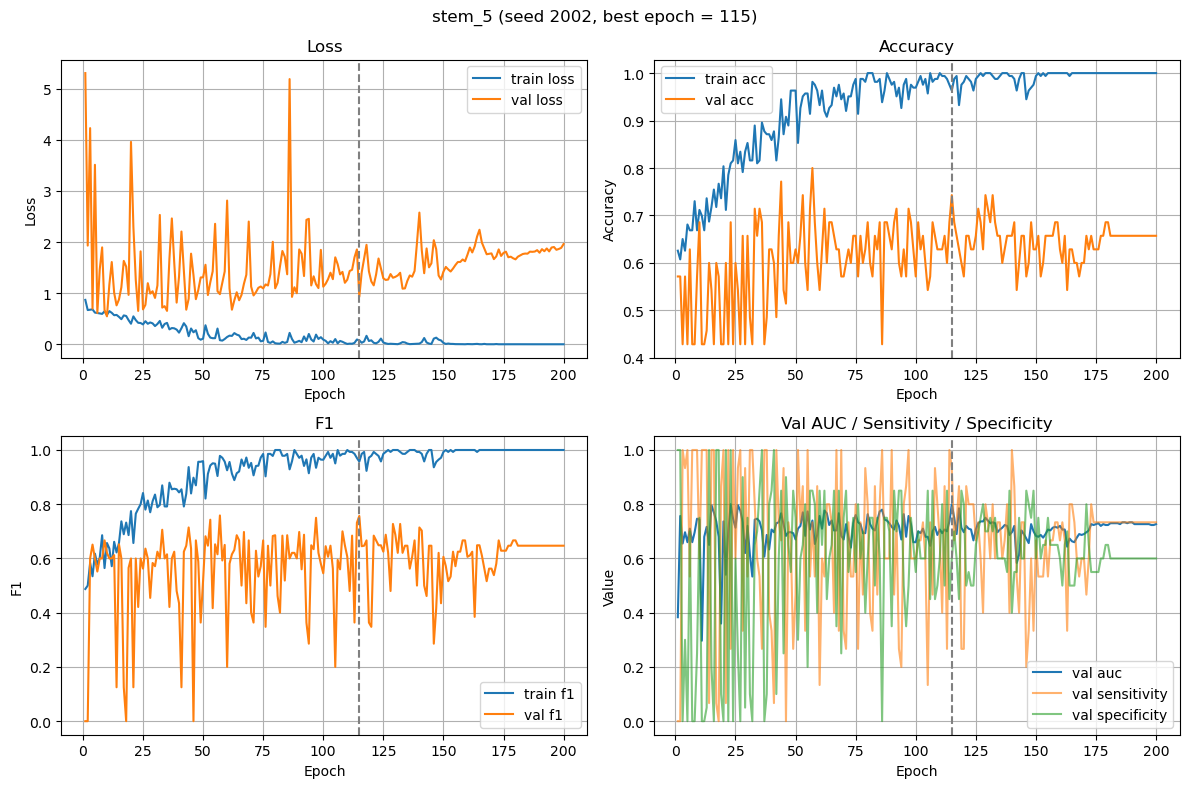

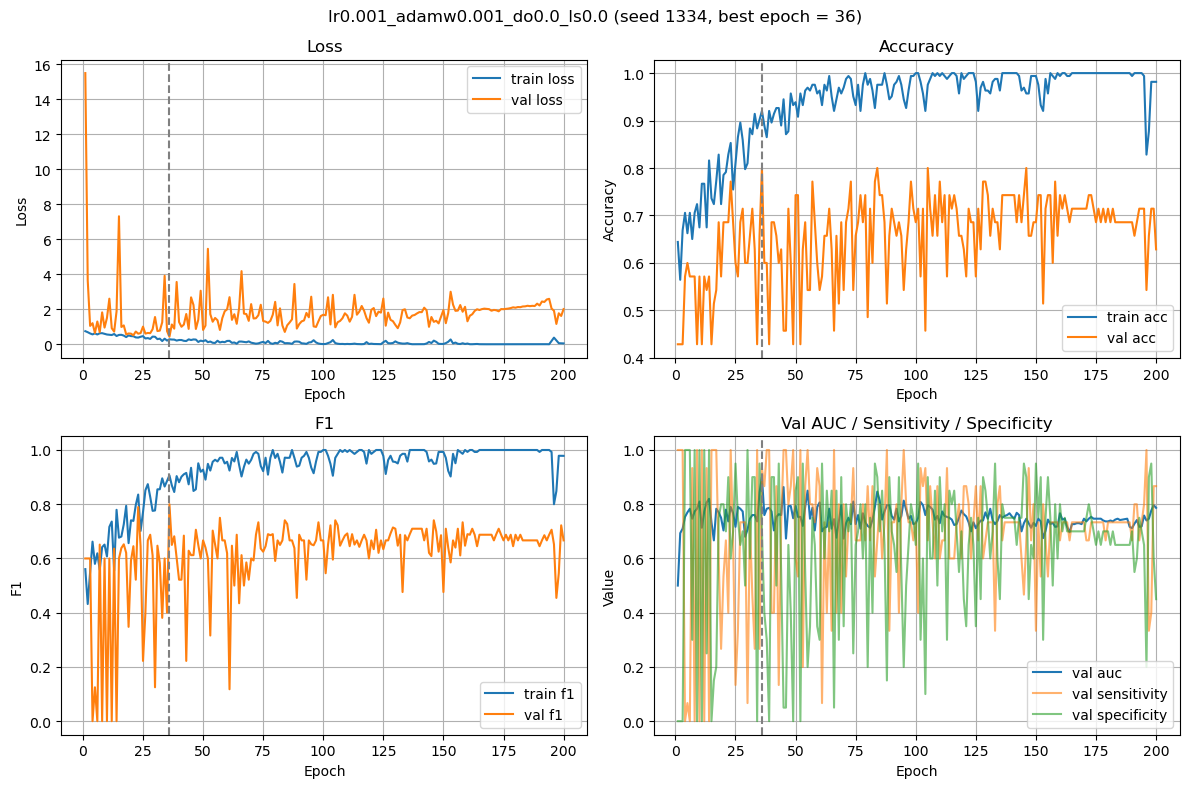

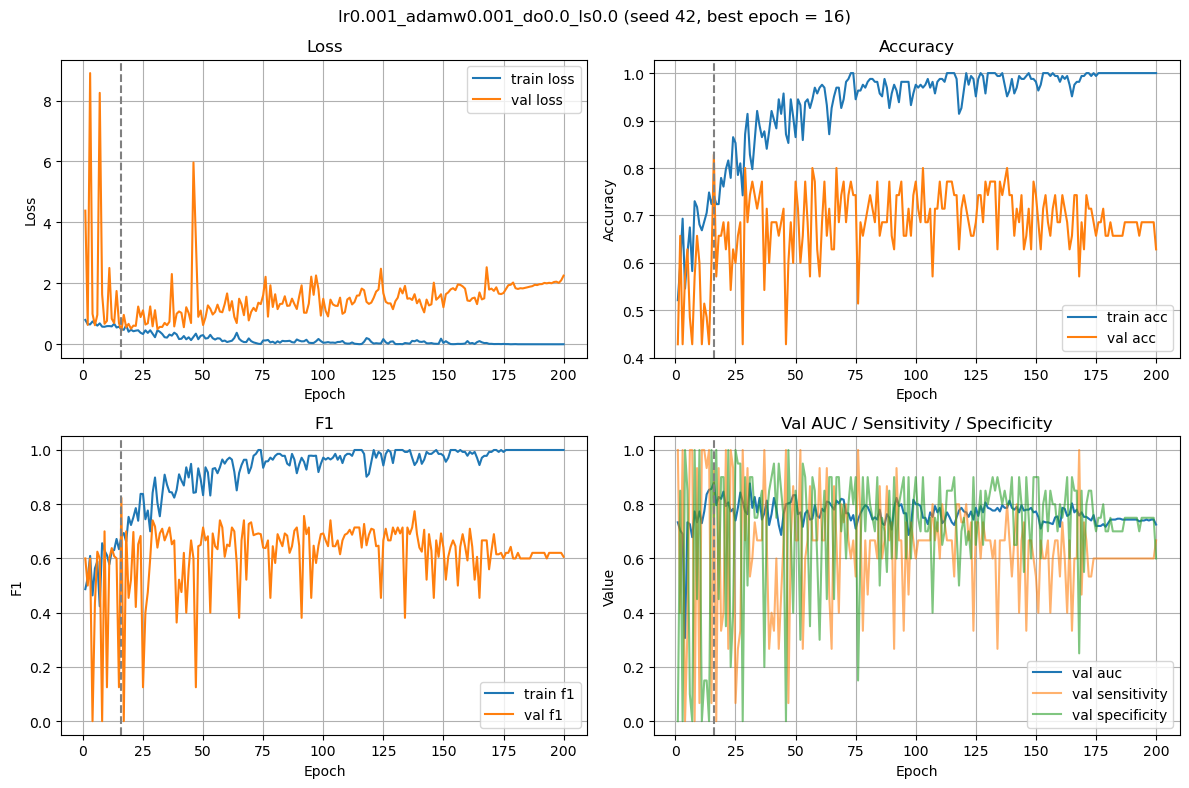

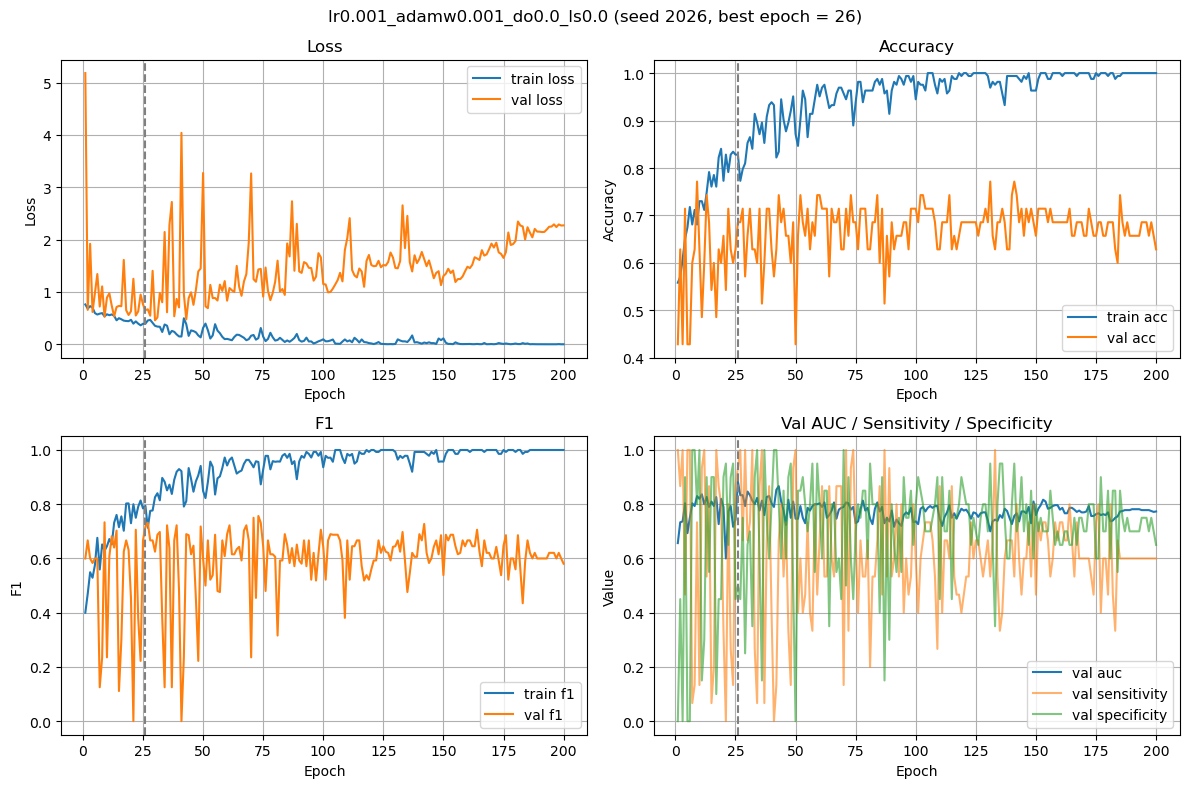

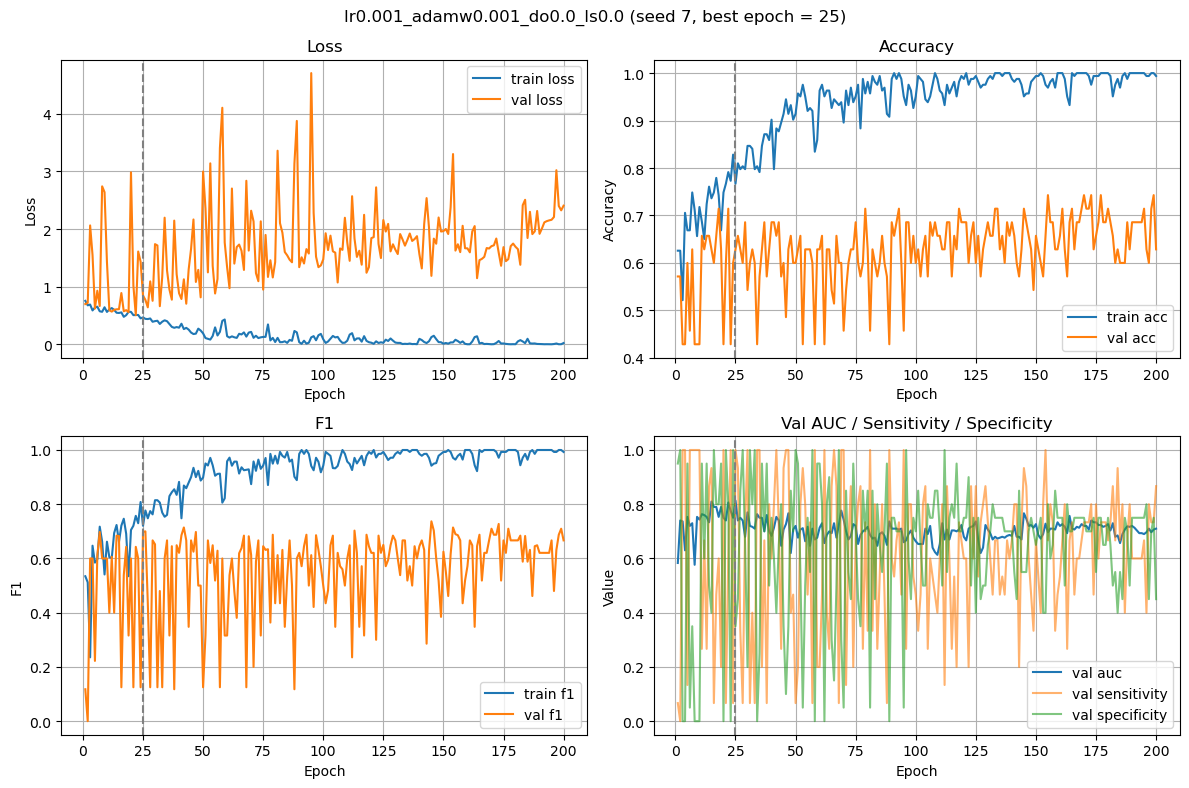

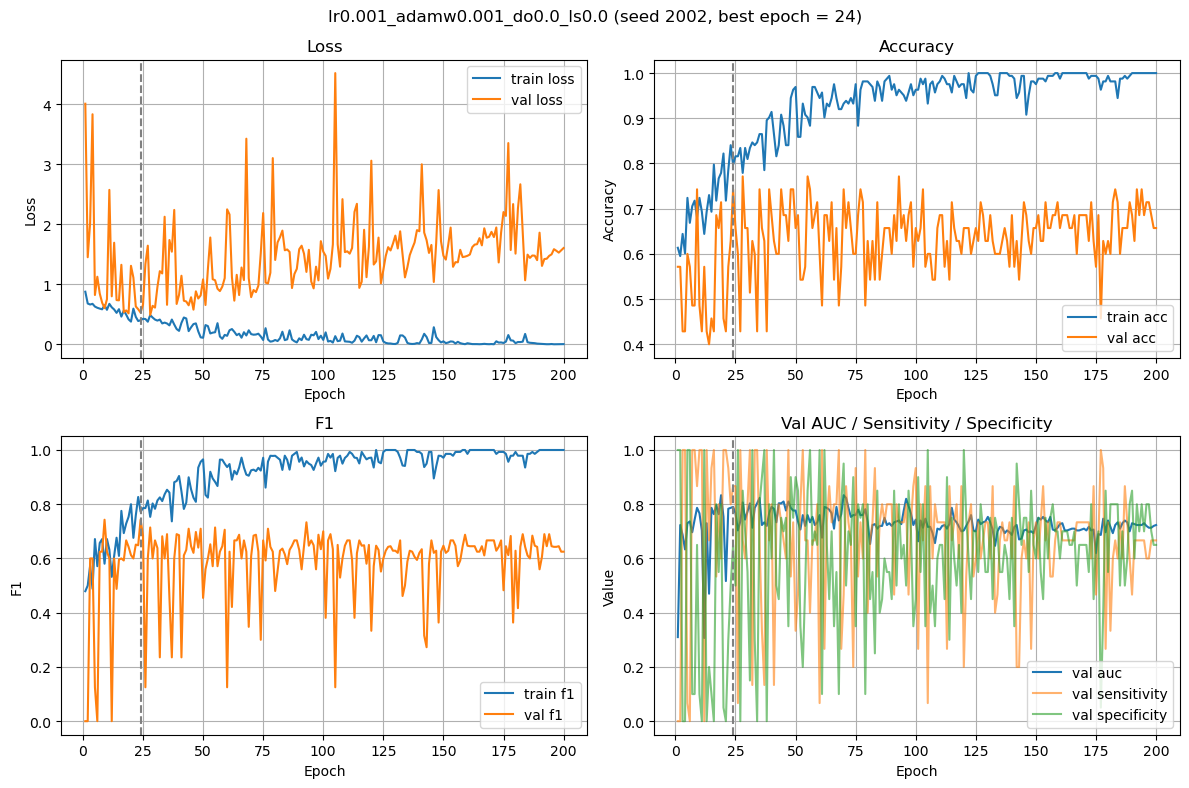

In [12]:
# กราฟ 2x2 ของแต่ละ seed ในแต่ละระดับ เก็บในโฟลเดอร์ figures ของระดับนั้น
show_names = set(all_runs)                                              # ชุดมีน้อย แสดงกราฟทุกชุด
for name in all_runs:
    fig_dir = os.path.join(EXP_DIR, name, "figures")
    os.makedirs(fig_dir, exist_ok=True)

    for r in all_runs[name]:
        h = r["history"]
        best_epoch = r["best_epoch"]
        epochs_x = range(1, len(h["train_loss"]) + 1)

        plt.figure(figsize=(12, 8))

        plt.subplot(2, 2, 1)
        plt.plot(epochs_x, h["train_loss"], label="train loss")
        plt.plot(epochs_x, h["val_loss"], label="val loss")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Loss")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 2)
        plt.plot(epochs_x, h["train_acc"], label="train acc")
        plt.plot(epochs_x, h["val_acc"], label="val acc")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Accuracy")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 3)
        plt.plot(epochs_x, h["train_f1"], label="train f1")
        plt.plot(epochs_x, h["val_f1"], label="val f1")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("F1")
        plt.title("F1")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 4)
        plt.plot(epochs_x, h["val_auc"], label="val auc")
        plt.plot(epochs_x, h["val_sens"], label="val sensitivity", alpha=0.6)
        plt.plot(epochs_x, h["val_spec"], label="val specificity", alpha=0.6)
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Value")
        plt.title("Val AUC / Sensitivity / Specificity")
        plt.grid(True)
        plt.legend()

        plt.suptitle(f"{name} (seed {r['seed']}, best epoch = {best_epoch})")
        plt.tight_layout()
        plt.savefig(os.path.join(fig_dir, f"curves_seed{r['seed']}.png"), dpi=150)
        if name in show_names:
            plt.show()
        plt.close()

## วิธีอ่านผล

## Test (ทำครั้งเดียว หลังเลือกระดับจาก val แล้ว)

เปิด test ไปแล้ว แสดงผลจากไฟล์ runs_resnet18_3D/test_stem_5.csv (ไม่ประเมินซ้ำ)


,seed,AUC,F1,Accuracy,Sensitivity,Specificity,TN,FP,FN,TP
0,1334,0.775,0.625,0.667,0.667,0.667,14,7,5,10
1,42,0.860,0.743,0.750,0.867,0.667,14,7,2,13
2,2026,0.794,0.538,0.667,0.467,0.810,17,4,8,7
3,7,0.667,0.533,0.611,0.533,0.667,14,7,7,8
4,2002,0.851,0.824,0.833,0.933,0.762,16,5,1,14



ResNet18 3D Evaluation (Test, mean ± SD ข้าม 5 seed)
AUC         : 0.7892 ± 0.0776
F1          : 0.6526 ± 0.1278
Accuracy    : 0.7056 ± 0.0870
Sensitivity : 0.6933 ± 0.2033
Specificity : 0.7143 ± 0.0673
Confusion Matrix (เฉลี่ยข้าม seed): TN=15.0, FP=6.0, FN=4.6, TP=10.4


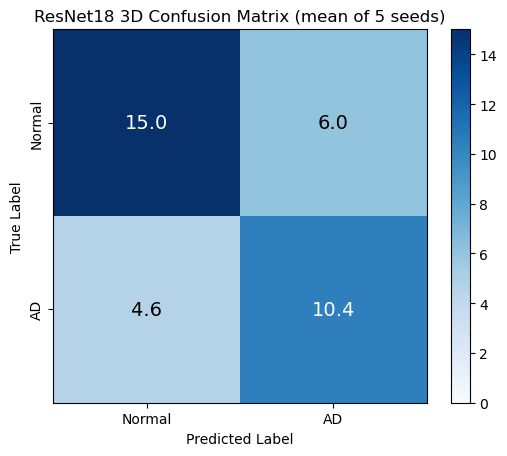

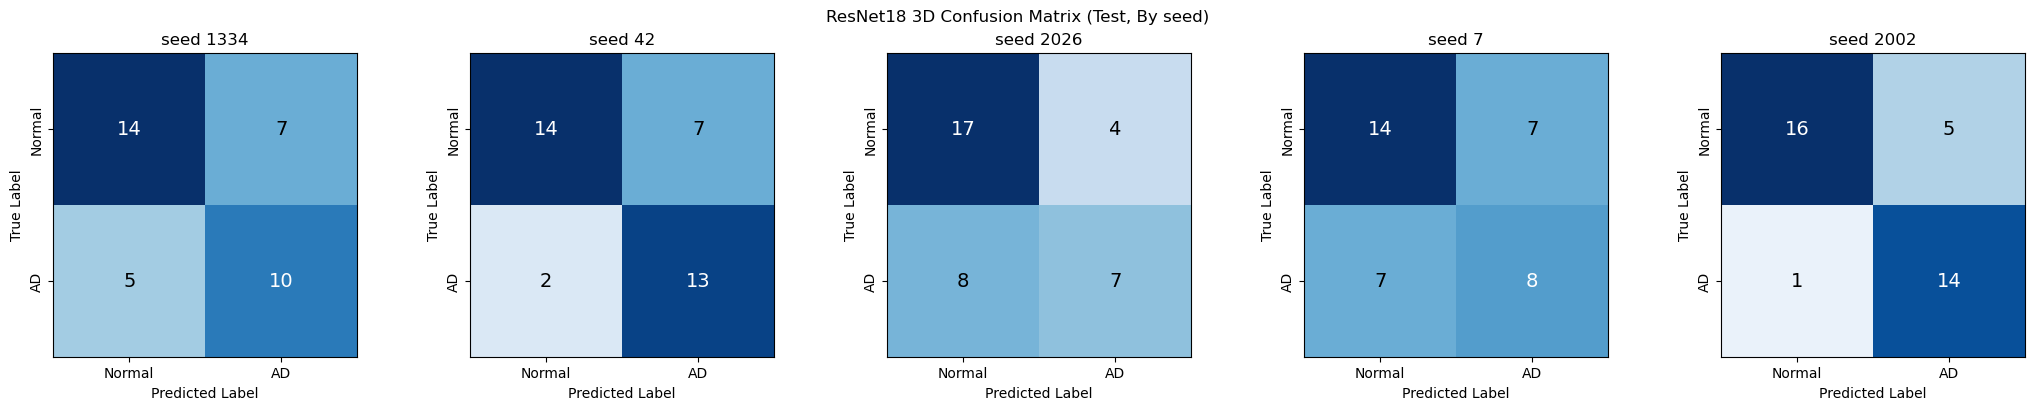

In [13]:
RUN_TEST = True
TEST_LEVEL = "stem_5"      # ล็อกแล้ว ห้ามแก้หลังเห็นผล test
MODEL_NAME = "ResNet18 3D"
TEST_CSV = os.path.join(EXP_DIR, f"test_{TEST_LEVEL}.csv")

def show_test_report(tt, name, out_dir, tag):
    # ตารางผลรายค่าเริ่มต้นสุ่ม + สรุป mean ± SD + ภาพ Confusion Matrix
    display(tt.round(3))
    print(f"\n{name} Evaluation (Test, mean ± SD ข้าม {len(tt)} seed)")
    for m in METRICS:
        print(f"{m:12s}: {tt[m].mean():.4f} ± {tt[m].std(ddof=1):.4f}")
    cms = [np.array([[r.TN, r.FP], [r.FN, r.TP]]) for r in tt.itertuples()]
    mean_cm = np.mean(cms, axis=0)
    print(f"Confusion Matrix (เฉลี่ยข้าม seed): TN={mean_cm[0,0]:.1f}, FP={mean_cm[0,1]:.1f}, FN={mean_cm[1,0]:.1f}, TP={mean_cm[1,1]:.1f}")

    def draw(ax, cm, title, fmt, colorbar=False):
        im = ax.imshow(cm, cmap="Blues", vmin=0)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "AD"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "AD"], rotation=90, va="center")
        ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
        ax.set_title(title)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
        if colorbar:
            plt.colorbar(im, ax=ax)

    # ภาพเดียว: เฉลี่ยข้าม seed
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    draw(ax, mean_cm, f"{name} Confusion Matrix (mean of {len(tt)} seeds)", ".1f", colorbar=True)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"confusion_matrix_{tag}_mean.png"), dpi=200)
    plt.show()

    # แยกรายค่าเริ่มต้นสุ่ม
    fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 4))
    for ax, cm, r in zip(np.atleast_1d(axes), cms, tt.itertuples()):
        draw(ax, cm, f"seed {r.seed}", "d")
    fig.suptitle(f"{name} Confusion Matrix (Test, By seed)")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"confusion_matrix_{tag}_per_seed.png"), dpi=200)
    plt.show()

if RUN_TEST:
    if os.path.exists(TEST_CSV):
        # เปิด test ไปแล้ว: อ่านผลจากไฟล์ที่บันทึกไว้ ไม่ประเมินซ้ำ
        print(f"เปิด test ไปแล้ว แสดงผลจากไฟล์ {TEST_CSV} (ไม่ประเมินซ้ำ)")
        test_table = pd.read_csv(TEST_CSV)
    else:
        assert TEST_LEVEL in RUN_LIST, "ใส่ชื่อระดับที่เลือกใน TEST_LEVEL ก่อน"
        test_data = MRIDataset(test_ids, train=False)
        test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
        criterion = nn.CrossEntropyLoss()
        test_rows = []
        for SEED in SEEDS:
            pt = os.path.join(EXP_DIR, TEST_LEVEL, "models", f"seed{SEED}_best.pt")
            model = make_model(EXPERIMENTS[TEST_LEVEL]["STEM_KERNEL"], EXPERIMENTS[TEST_LEVEL]["DROPOUT"]).to(device)
            model.load_state_dict(torch.load(pt, map_location=device))      # น้ำหนักของ epoch ที่เลือกจาก val
            t = evaluate(model, test_loader, criterion)
            test_rows.append({"seed": SEED, **{m: t[m] for m in METRICS}, "TN": t["TN"], "FP": t["FP"], "FN": t["FN"], "TP": t["TP"]})
        test_table = pd.DataFrame(test_rows)
        test_table.to_csv(TEST_CSV, index=False)
    show_test_report(test_table, MODEL_NAME, EXP_DIR, "ResNet18_3D")
else:
    print("ยังไม่เปิด test")
